===== STAR SCHEMA DESIGN =====


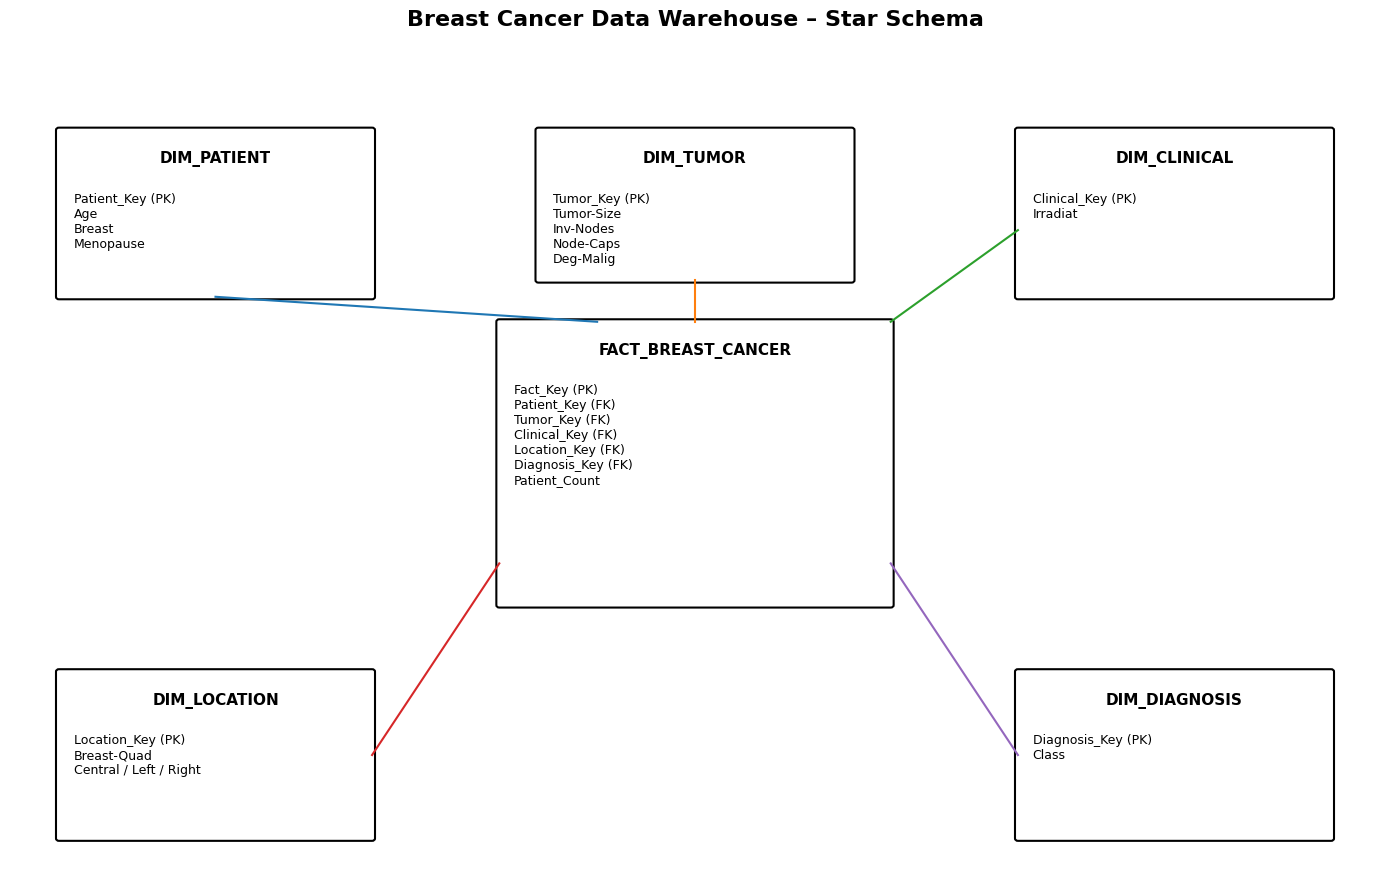

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

print("===== STAR SCHEMA DESIGN =====")

fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")

def draw_table(x, y, width, height, title, fields):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.03",
        linewidth=1.5,
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(
        x + width/2, y + height - 0.35,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x + 0.15, y + height - 0.75,
        "\n".join(fields),
        ha="left",
        va="top",
        fontsize=9
    )

# Fact table
draw_table(
    5, 3.3, 4, 3.4,
    "FACT_BREAST_CANCER",
    [
        "Fact_Key (PK)",
        "Patient_Key (FK)",
        "Tumor_Key (FK)",
        "Clinical_Key (FK)",
        "Location_Key (FK)",
        "Diagnosis_Key (FK)",
        "Patient_Count"
    ]
)

# Dimensions
draw_table(
    0.5, 7, 3.2, 2,
    "DIM_PATIENT",
    [
        "Patient_Key (PK)",
        "Age",
        "Breast",
        "Menopause"
    ]
)

draw_table(
    5.4, 7.2, 3.2, 1.8,
    "DIM_TUMOR",
    [
        "Tumor_Key (PK)",
        "Tumor-Size",
        "Inv-Nodes",
        "Node-Caps",
        "Deg-Malig"
    ]
)

draw_table(
    10.3, 7, 3.2, 2,
    "DIM_CLINICAL",
    [
        "Clinical_Key (PK)",
        "Irradiat"
    ]
)

draw_table(
    0.5, 0.5, 3.2, 2,
    "DIM_LOCATION",
    [
        "Location_Key (PK)",
        "Breast-Quad",
        "Central / Left / Right"
    ]
)

draw_table(
    10.3, 0.5, 3.2, 2,
    "DIM_DIAGNOSIS",
    [
        "Diagnosis_Key (PK)",
        "Class"
    ]
)

# Relationship lines
connections = [
    ((2.1, 7), (6.0, 6.7)),
    ((7.0, 7.2), (7.0, 6.7)),
    ((10.3, 7.8), (9.0, 6.7)),
    ((3.7, 1.5), (5.0, 3.8)),
    ((10.3, 1.5), (9.0, 3.8))
]

for start, end in connections:
    ax.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        linewidth=1.5
    )

plt.title(
    "Breast Cancer Data Warehouse – Star Schema",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()

In [3]:
import sqlite3
import os

print("===== CREATING DATA WAREHOUSE =====")

# Create the warehouse folder if it does not exist
warehouse_folder = "../04_Data_Warehouse"
os.makedirs(warehouse_folder, exist_ok=True)

# Database path
database_path = os.path.join(
    warehouse_folder,
    "breast_cancer_warehouse.db"
)

# Create / connect to SQLite database
conn = sqlite3.connect(database_path)
cursor = conn.cursor()

print("Database connected successfully!")
print("Database location:", database_path)


# ==========================================
# DIMENSION 1: PATIENT
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Patient (
    Patient_Key INTEGER PRIMARY KEY,
    Age REAL,
    Breast INTEGER,
    Menopause_ge40 INTEGER,
    Menopause_lt40 INTEGER,
    Menopause_premeno INTEGER
)
""")


# ==========================================
# DIMENSION 2: TUMOR
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Tumor (
    Tumor_Key INTEGER PRIMARY KEY,
    Tumor_Size REAL,
    Inv_Nodes REAL,
    Node_Caps INTEGER,
    Deg_Malig INTEGER
)
""")


# ==========================================
# DIMENSION 3: CLINICAL
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Clinical (
    Clinical_Key INTEGER PRIMARY KEY,
    Irradiat INTEGER
)
""")


# ==========================================
# DIMENSION 4: LOCATION
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Location (
    Location_Key INTEGER PRIMARY KEY,
    Breast_Quad_central INTEGER,
    Breast_Quad_left_low INTEGER,
    Breast_Quad_left_up INTEGER,
    Breast_Quad_right_low INTEGER,
    Breast_Quad_right_up INTEGER
)
""")


# ==========================================
# DIMENSION 5: DIAGNOSIS
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Diagnosis (
    Diagnosis_Key INTEGER PRIMARY KEY,
    Class INTEGER
)
""")


# ==========================================
# FACT TABLE
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS Fact_Breast_Cancer (
    Fact_Key INTEGER PRIMARY KEY,
    Patient_Key INTEGER,
    Tumor_Key INTEGER,
    Clinical_Key INTEGER,
    Location_Key INTEGER,
    Diagnosis_Key INTEGER,
    Patient_Count INTEGER,

    FOREIGN KEY (Patient_Key)
        REFERENCES Dim_Patient(Patient_Key),

    FOREIGN KEY (Tumor_Key)
        REFERENCES Dim_Tumor(Tumor_Key),

    FOREIGN KEY (Clinical_Key)
        REFERENCES Dim_Clinical(Clinical_Key),

    FOREIGN KEY (Location_Key)
        REFERENCES Dim_Location(Location_Key),

    FOREIGN KEY (Diagnosis_Key)
        REFERENCES Dim_Diagnosis(Diagnosis_Key)
)
""")


# Save changes
conn.commit()

print("\nData warehouse created successfully!")

print("\nTables created:")
print("- Dim_Patient")
print("- Dim_Tumor")
print("- Dim_Clinical")
print("- Dim_Location")
print("- Dim_Diagnosis")
print("- Fact_Breast_Cancer")

print("\nDatabase file:")
print(database_path)

===== CREATING DATA WAREHOUSE =====
Database connected successfully!
Database location: ../04_Data_Warehouse\breast_cancer_warehouse.db

Data warehouse created successfully!

Tables created:
- Dim_Patient
- Dim_Tumor
- Dim_Clinical
- Dim_Location
- Dim_Diagnosis
- Fact_Breast_Cancer

Database file:
../04_Data_Warehouse\breast_cancer_warehouse.db


In [4]:
print("===== DATA WAREHOUSE SCHEMA VERIFICATION =====")

# Get all tables in the database
cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""")

tables = cursor.fetchall()

print("\nTables in the warehouse:")

for table in tables:
    print("-", table[0])


# Display columns for each table
print("\n===== TABLE STRUCTURES =====")

for table in tables:
    table_name = table[0]

    print(f"\n{table_name}:")

    cursor.execute(f"PRAGMA table_info({table_name})")
    columns = cursor.fetchall()

    for column in columns:
        column_id, name, data_type, not_null, default_value, primary_key = column

        key = " PRIMARY KEY" if primary_key else ""

        print(f"  - {name} ({data_type}){key}")


# Display foreign keys
print("\n===== FOREIGN KEY RELATIONSHIPS =====")

cursor.execute("PRAGMA foreign_key_list(Fact_Breast_Cancer)")
foreign_keys = cursor.fetchall()

for fk in foreign_keys:
    print(
        f"Fact_Breast_Cancer.{fk[3]} "
        f"→ {fk[2]}.{fk[4]}"
    )

print("\n===== SCHEMA VERIFICATION COMPLETED =====")

===== DATA WAREHOUSE SCHEMA VERIFICATION =====

Tables in the warehouse:
- Dim_Clinical
- Dim_Diagnosis
- Dim_Location
- Dim_Patient
- Dim_Tumor
- Fact_Breast_Cancer

===== TABLE STRUCTURES =====

Dim_Clinical:
  - Clinical_Key (INTEGER) PRIMARY KEY
  - Irradiat (INTEGER)

Dim_Diagnosis:
  - Diagnosis_Key (INTEGER) PRIMARY KEY
  - Class (INTEGER)

Dim_Location:
  - Location_Key (INTEGER) PRIMARY KEY
  - Breast_Quad_central (INTEGER)
  - Breast_Quad_left_low (INTEGER)
  - Breast_Quad_left_up (INTEGER)
  - Breast_Quad_right_low (INTEGER)
  - Breast_Quad_right_up (INTEGER)

Dim_Patient:
  - Patient_Key (INTEGER) PRIMARY KEY
  - Age (REAL)
  - Breast (INTEGER)
  - Menopause_ge40 (INTEGER)
  - Menopause_lt40 (INTEGER)
  - Menopause_premeno (INTEGER)

Dim_Tumor:
  - Tumor_Key (INTEGER) PRIMARY KEY
  - Tumor_Size (REAL)
  - Inv_Nodes (REAL)
  - Node_Caps (INTEGER)
  - Deg_Malig (INTEGER)

Fact_Breast_Cancer:
  - Fact_Key (INTEGER) PRIMARY KEY
  - Patient_Key (INTEGER)
  - Tumor_Key (INTEGER)
